# Using generic loader for NeXus files
## I09 data example

HdfMap maps out the entries in a NeXus file, finds default data and area detector data,
then creates a namespace of all the data in the file.

See https://github.com/DiamondLightSource/hdfmap

Or install directly:

```
pip install hdfmap
```

In [27]:
# hdfmap example
import hdfmap

filename = '/dls/i09-2/data/2026/cm44152-4/i09-2-7200.nxs'

m = hdfmap.create_nexus_map(filename)

print(m.image_data)  # returns area detector paths

# Detector data
with hdfmap.load_hdf(filename) as hdf:
    data = m.get_image(hdf, index=())  # uses the first area detector
    # For scan_command, this could be in a couple of different places, so we use an expression
    # this is a "safe" evaluator that evaluates an expression using the Nexus namespace
    scan_command = m.eval(hdf, '(user_command|scan_command)')  

print(f"Detector data shape: {data.shape}")
print(f"Scan Command: {scan_command}")

{'dld': '/entry/instrument/dld/data', 'IMAGE': '/entry/instrument/dld/data'}
Detector data shape: (201, 1212, 1212)
Scan Command: scan Kenergy 101 106 0.025 dld 20 checkbeam sm6iamp27


{'focus': '/entry/focus/value', 'count_time': '/entry/instrument/dld_total/count_time', 'fixed_roi_total': '/entry/instrument/dld_total/fixed_roi_total'}


Text(0.5, 1.0, '/dls/i09-2/data/2026/cm44152-4/i09-2-7193.nxs')

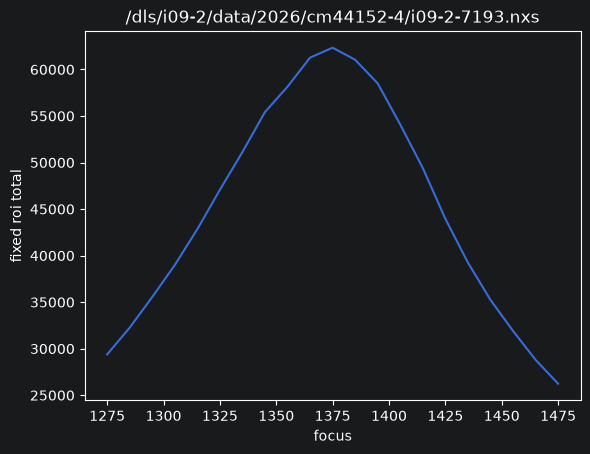

In [24]:
# scan with detector total
filename = '/dls/i09-2/data/2026/cm44152-4/i09-2-7193.nxs'

m = hdfmap.create_nexus_map(filename)

# Scannable data paths
print(m.scannables)

import matplotlib.pyplot as plt

with hdfmap.load_hdf(filename) as hdf:
    data = m.get_scannables(hdf)

plt.figure()
plt.plot(data['focus'], data['fixed_roi_total'])
plt.xlabel('focus')
plt.ylabel('fixed roi total')
plt.title(filename)

## Example using mmg_toolbox

Tools in mmg_toolbox provide a simpler interface to interact withd data.

See https://github.com/DiamondLightSource/mmg_toolbox

To install, simply:
```
pip install mmg_toolbox
```

In [30]:
from mmg_toolbox import data_file_reader

filename = '/dls/i09-2/data/2026/cm44152-4/i09-2-7193.nxs'

scan = data_file_reader(filename)

print(scan)

cmd = scan('scan_command')
print(f"\nScan command: {cmd}")


i09-2-7193.nxs
/dls/i09-2/data/2026/cm44152-4/i09-2-7193.nxs
2026-10-13 18:35:06.006000
scan_command = scan focus 1275.0 1475.0 10 dld_total 1
axes = /entry/focus/focus
signal = /entry/focus/value
detector = none
shape = (21,)


Scan command: scan focus 1275.0 1475.0 10 dld_total 1


<Axes: title={'center': '#7193\nscan focus 1275.0 1475.0 10 dld_total 1'}, xlabel='focus', ylabel='fixed_roi_total'>

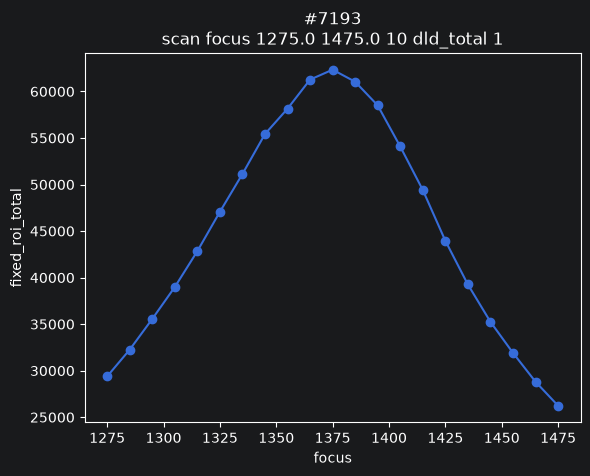

In [12]:
# Note that for the current I09-2 files, the @default attributes in the NeXus file
# do not appear to be set correctly, so you need to specify which axes to plot.
# Normally you can omit the axes and signal values.

scan.plot('focus', 'fixed_roi_total')


i09-2-7200.nxs
/dls/i09-2/data/2026/cm44152-4/i09-2-7200.nxs
2026-10-13 23:05:34.050000
scan_command = scan Kenergy 101 106 0.025 dld 20 checkbeam sm6iamp27
axes = /entry/dld/Kenergy
signal = /entry/dld/data
detector = dld
shape = (201,)



<Axes: title={'center': '#7200\nscan Kenergy 101 106 0.025 dld 20 checkbeam sm6iamp27'}, xlabel='Kenergy', ylabel='dld'>

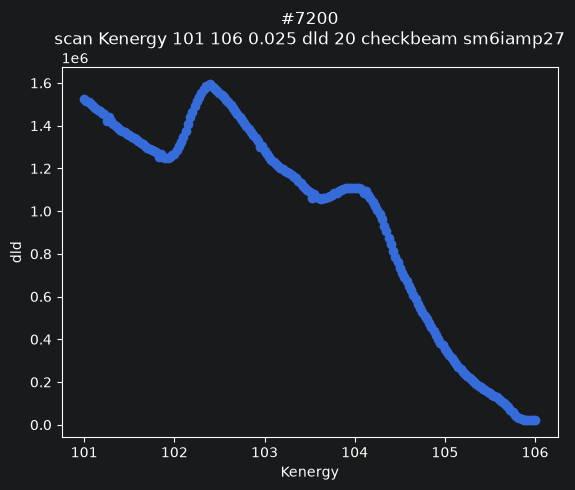

In [19]:
# image data
filename = '/dls/i09-2/data/2026/cm44152-4/i09-2-7200.nxs'

scan2 = data_file_reader(filename)
print(scan2)

# Use default plotting
scan2.plot()

<Axes: title={'center': '#7200\nKenergy [101] = 103.52500000000057'}>

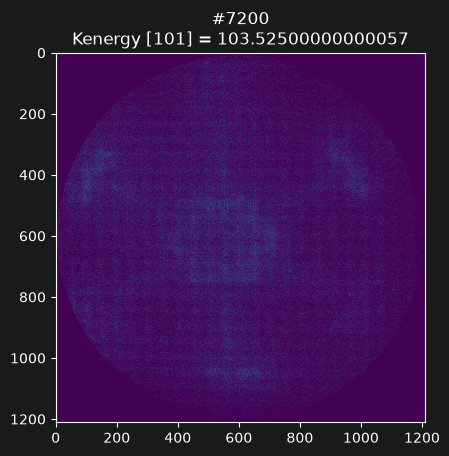

In [22]:
# Plot image
scan2.plot.image(101)